# Stage 2: Overall Glucose Level (Participant 001)

Now that the data has passed the quality checks, we describe the overall glucose level.

| # | Question |
|---|---|
| Q1 | What are the mean, median, min, and max glucose? |
| Q2 | What are the 25th and 75th percentiles (the "typical" range)? |
| Q3 | What does the distribution look like? Is it skewed toward high values? |
| Q4 | What % of time is spent in each range: < 70, 70–140, 140–180, > 180? |
| Q5 | What is the GMI, and how does it compare with the measured HbA1c? |

## Setup

We load the cleaned file saved at the end of Stage 1 (`glucose_001_clean.csv`). If it isn't found, the cell falls back to the raw Dexcom file and applies the same basic cleaning.

`Demographics.csv` holds each participant's measured HbA1c, which we need for Q5.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PID = "001"
DATA_DIR = "../../../datasets/big-ideas-glycemic-wearable"
CLEAN_PATH = f"../clean_data/glucose_{PID}_clean.csv"
RAW_PATH = f"{DATA_DIR}/{PID}/Dexcom_{PID}.csv"
DEMO_PATH = f"{DATA_DIR}/Demographics.csv"

In [2]:
if os.path.exists(CLEAN_PATH):
    glu = pd.read_csv(CLEAN_PATH, parse_dates=["timestamp"])
    print("Loaded cleaned file from Stage 1")
else:
    raw = pd.read_csv(RAW_PATH, skiprows=range(1, 13))
    raw = raw[raw["Event Type"] == "EGV"]
    glu = pd.DataFrame({
        "timestamp": pd.to_datetime(raw["Timestamp (YYYY-MM-DDThh:mm:ss)"]),
        "glucose": pd.to_numeric(raw["Glucose Value (mg/dL)"], errors="coerce"),
    }).dropna().drop_duplicates("timestamp")
    print("Stage 1 file not found, loaded raw Dexcom file instead")

glu = glu.sort_values("timestamp").reset_index(drop=True)
g = glu["glucose"]
print("Readings:", len(g))
glu.head()

Loaded cleaned file from Stage 1
Readings: 2561


,timestamp,glucose
0,2020-02-13 17:23:32,61.0
1,2020-02-13 17:28:32,59.0
2,2020-02-13 17:33:32,58.0
3,2020-02-13 17:38:32,59.0
4,2020-02-13 17:43:31,63.0


---
## Q1: Mean, median, min, and max

- **Mean** is the average level. It is pulled up by spikes.
- **Median** is the middle value. It is less affected by spikes, so it better represents a "normal moment".
- If the mean is clearly higher than the median, a few high spikes are lifting the average.

In [3]:
stats_q1 = pd.Series({
    "mean": g.mean(),
    "median": g.median(),
    "min": g.min(),
    "max": g.max(),
    "std": g.std(),
}).round(1)

print(stats_q1.to_string())
print(f"\nMean − median = {g.mean() - g.median():.1f} mg/dL")

mean      106.1
median    105.0
min        46.0
max       155.0
std        15.8

Mean − median = 1.1 mg/dL


In [4]:
# When did the min and max occur?
print("Lowest reading: ", glu.loc[g.idxmin(), "timestamp"], f"({g.min():.0f} mg/dL)")
print("Highest reading:", glu.loc[g.idxmax(), "timestamp"], f"({g.max():.0f} mg/dL)")

Lowest reading:  2020-02-16 08:08:29 (46 mg/dL)
Highest reading: 2020-02-19 16:53:25 (155 mg/dL)


---
## Q2: Percentiles and the typical range

The **25th–75th percentile range** (interquartile range, IQR) is where glucose sits half of the time. It is a good definition of the participant's "typical" range.

The 5th and 95th percentiles show the extremes without being dominated by one unusual reading.

In [5]:
pcts = g.quantile([0.05, 0.25, 0.50, 0.75, 0.95]).round(1)
pcts.index = ["5th", "25th", "50th (median)", "75th", "95th"]
print(pcts.to_string())

p25, p75 = g.quantile(0.25), g.quantile(0.75)
print(f"\nTypical range (IQR): {p25:.0f} – {p75:.0f} mg/dL  (width {p75 - p25:.0f} mg/dL)")

5th               85.0
25th              95.0
50th (median)    105.0
75th             114.0
95th             137.0

Typical range (IQR): 95 – 114 mg/dL  (width 19 mg/dL)


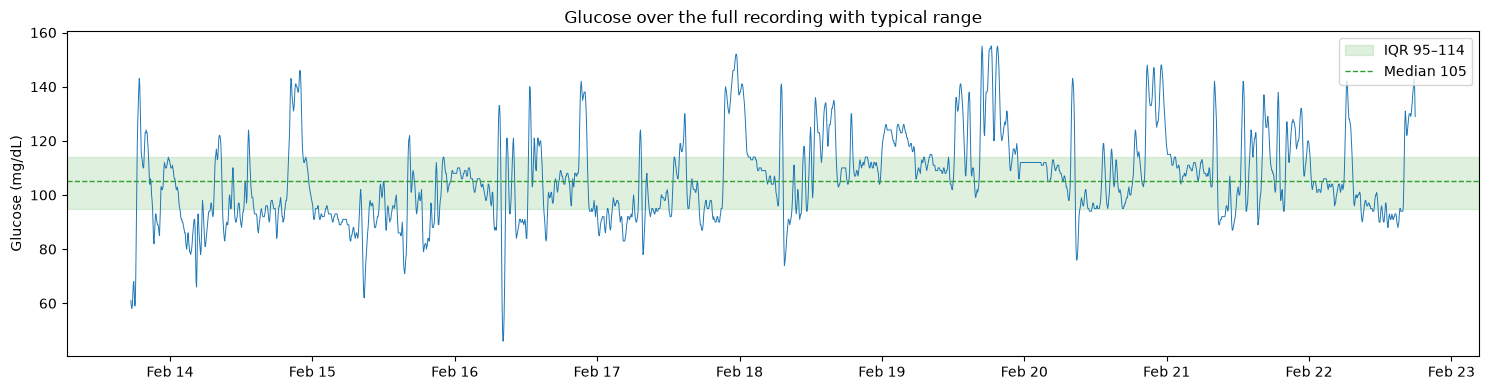

In [6]:
# Glucose trace with the typical range shaded
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(glu["timestamp"], g, lw=0.7, color="tab:blue")
ax.axhspan(p25, p75, color="tab:green", alpha=0.15, label=f"IQR {p25:.0f}–{p75:.0f}")
ax.axhline(g.median(), color="tab:green", ls="--", lw=1, label=f"Median {g.median():.0f}")
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title("Glucose over the full recording with typical range")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

---
## Q3: Distribution shape and skewness

Glucose distributions are often **right-skewed**: most readings cluster at a normal baseline, with a tail of higher post-meal values.

**Skewness** measures this:
- around 0 → roughly symmetric
- between 0.5 and 1 → moderately right-skewed (tail toward high values)
- above 1 → strongly right-skewed
- negative → tail toward low values

In [7]:
skew = g.skew()

if abs(skew) < 0.5:
    shape = "roughly symmetric"
elif skew >= 1:
    shape = "strongly right-skewed (long tail of high values)"
elif skew > 0:
    shape = "moderately right-skewed (tail of high values)"
elif skew <= -1:
    shape = "strongly left-skewed (long tail of low values)"
else:
    shape = "moderately left-skewed (tail of low values)"

print(f"Skewness: {skew:.2f} → {shape}")

Skewness: 0.48 → roughly symmetric


/tmp/ipykernel_43910/1911861830.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(g, vert=True, widths=0.5)


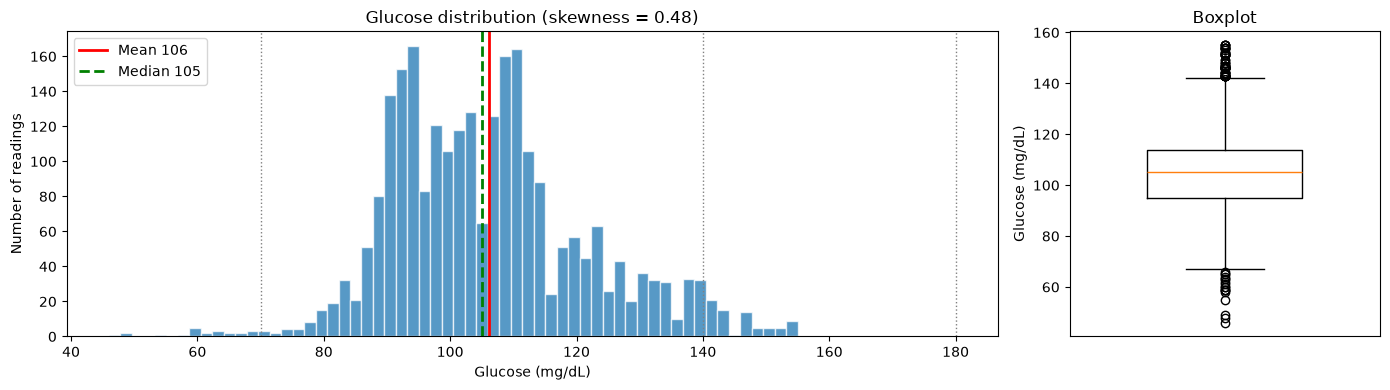

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})

# Histogram with mean/median and range boundaries
axes[0].hist(g, bins=60, color="tab:blue", alpha=0.75, edgecolor="white")
axes[0].axvline(g.mean(), color="red", lw=2, label=f"Mean {g.mean():.0f}")
axes[0].axvline(g.median(), color="green", lw=2, ls="--", label=f"Median {g.median():.0f}")
for t in (70, 140, 180):
    axes[0].axvline(t, color="gray", ls=":", lw=1)
axes[0].set_xlabel("Glucose (mg/dL)")
axes[0].set_ylabel("Number of readings")
axes[0].set_title(f"Glucose distribution (skewness = {skew:.2f})")
axes[0].legend()

# Boxplot: box = IQR, whiskers = typical spread, dots = outliers
axes[1].boxplot(g, vert=True, widths=0.5)
axes[1].set_ylabel("Glucose (mg/dL)")
axes[1].set_xticks([])
axes[1].set_title("Boxplot")

plt.tight_layout()
plt.show()

Finding and counting outliers

In [9]:
g = glu["glucose"]

q1, q3 = g.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

low_out = glu[g < lower]
high_out = glu[g > upper]

print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}")
print(f"Fences: {lower:.1f} – {upper:.1f} mg/dL")
print(f"Low outliers:  {len(low_out)} ({len(low_out) / len(g) * 100:.1f}%)")
print(f"High outliers: {len(high_out)} ({len(high_out) / len(g) * 100:.1f}%)")

Q1 = 95, Q3 = 114, IQR = 19
Fences: 66.5 – 142.5 mg/dL
Low outliers:  18 (0.7%)
High outliers: 54 (2.1%)


Outlier readings usually come in runs, because one meal spike lasts several consecutive readings. Counting episodes is more meaningful than counting single readings:

In [11]:
def episodes(mask):
    run_id = (mask != mask.shift()).cumsum()
    runs = glu[mask].groupby(run_id[mask])
    return runs.agg(start=("timestamp", "first"),
                    end=("timestamp", "last"),
                    readings=("glucose", "size"),
                    extreme=("glucose", lambda s: s.max() if s.mean() > upper else s.min()))

high_ep = episodes(g > upper)
low_ep = episodes(g < lower)
print(f"High-outlier episodes: {len(high_ep)} | low-outlier episodes: {len(low_ep)}")
high_ep

High-outlier episodes: 12 | low-outlier episodes: 5


,start,end,readings,extreme
glucose,,,,
2,2020-02-13 18:48:32,2020-02-13 18:48:32,1,143.0
4,2020-02-14 20:23:30,2020-02-14 20:23:30,1,143.0
6,2020-02-14 21:48:30,2020-02-14 21:58:30,3,146.0
8,2020-02-17 22:48:27,2020-02-17 23:43:27,12,152.0
10,2020-02-19 16:43:26,2020-02-19 17:03:25,5,155.0
12,2020-02-19 17:53:25,2020-02-19 18:38:25,10,155.0
14,2020-02-19 19:13:25,2020-02-19 19:43:25,7,155.0
16,2020-02-20 08:08:25,2020-02-20 08:08:25,1,143.0
18,2020-02-20 20:38:25,2020-02-20 20:53:25,4,148.0


In [12]:
low_ep

,start,end,readings,extreme
glucose,,,,
1,2020-02-13 17:23:32,2020-02-13 17:43:31,5,58.0
3,2020-02-13 17:58:31,2020-02-13 18:08:32,3,59.0
5,2020-02-14 04:28:32,2020-02-14 04:28:32,1,66.0
7,2020-02-15 08:38:30,2020-02-15 08:48:30,3,62.0
9,2020-02-16 07:58:30,2020-02-16 08:23:30,6,46.0


To see when they happen, which usually explains them:

In [13]:
glu.loc[g > upper, "timestamp"].dt.hour.value_counts().sort_index()   # high: likely meal times
glu.loc[g < lower, "timestamp"].dt.date.value_counts()                # low: likely the Feb 16 dip

timestamp
2020-02-13    8
2020-02-16    6
2020-02-15    3
2020-02-14    1
Name: count, dtype: int64

---
## Q4: Time spent in each glucose range

Each reading represents 5 minutes, so the % of readings in a range equals the % of recorded time in that range. We also convert it to **hours per day**, which is often easier to picture.

| Range | mg/dL | Meaning |
|---|---|---|
| Low | < 70 | Hypoglycemia range |
| Normal | 70–140 | Typical for people without diabetes |
| Elevated | 140–180 | Common briefly after meals |
| High | > 180 | Notable spike for this population |

In [14]:
bins = [0, 70, 140, 180, np.inf]
labels = ["< 70 (low)", "70–140 (normal)", "140–180 (elevated)", "> 180 (high)"]
glu["range"] = pd.cut(g, bins=bins, labels=labels, right=False)

tir = glu["range"].value_counts(sort=False).rename("readings").to_frame()
tir["% of time"] = (tir["readings"] / len(glu) * 100).round(1)
tir["hours per day"] = (tir["% of time"] / 100 * 24).round(2)
tir["minutes total"] = tir["readings"] * 5
tir

,readings,% of time,hours per day,minutes total
range,,,,
< 70 (low),22,0.9,0.22,110
70–140 (normal),2445,95.5,22.92,12225
140–180 (elevated),94,3.7,0.89,470
> 180 (high),0,0.0,0.00,0


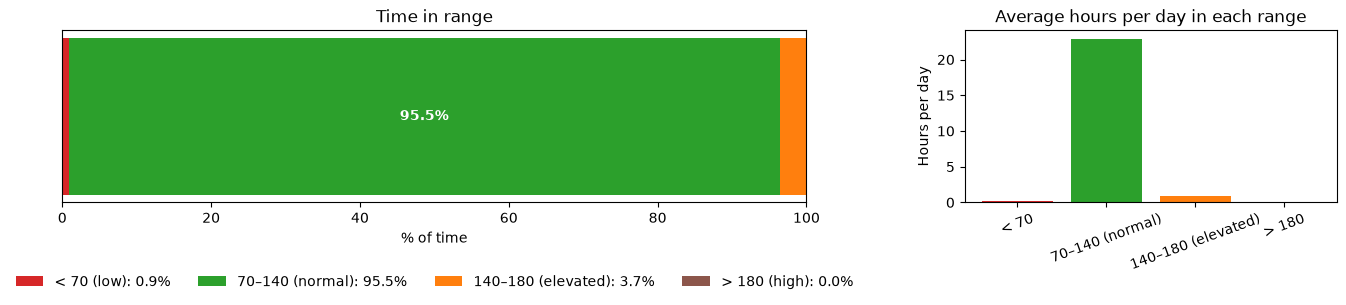

In [15]:
colors = ["#d62728", "#2ca02c", "#ff7f0e", "#8c564b"]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [2, 1]})

# Stacked horizontal bar (the standard way CGM reports show time in range)
left = 0
for (label, pct), c in zip(tir["% of time"].items(), colors):
    axes[0].barh(0, pct, left=left, color=c, label=f"{label}: {pct:.1f}%")
    if pct > 4:
        axes[0].text(left + pct / 2, 0, f"{pct:.1f}%", ha="center", va="center", color="white", weight="bold")
    left += pct
axes[0].set_xlim(0, 100)
axes[0].set_yticks([])
axes[0].set_xlabel("% of time")
axes[0].set_title("Time in range")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4, frameon=False)

# Hours per day
axes[1].bar(range(len(tir)), tir["hours per day"], color=colors)
axes[1].set_xticks(range(len(tir)))
axes[1].set_xticklabels([l.split(" ")[0] + " " + l.split(" ")[1] for l in labels], rotation=20)
axes[1].set_ylabel("Hours per day")
axes[1].set_title("Average hours per day in each range")

plt.tight_layout()
plt.show()

### Time in range per day

The overall percentages can hide differences between days. This table shows the same breakdown for each calendar day. The first and last days are partial, so their percentages are based on fewer readings.

In [16]:
daily_tir = (
    pd.crosstab(glu["timestamp"].dt.date.rename("date"), glu["range"], normalize="index")
    .reindex(columns=labels, fill_value=0) * 100
).round(1)
daily_tir["readings"] = glu.groupby(glu["timestamp"].dt.date).size().values
daily_tir

range,< 70 (low),70–140 (normal),140–180 (elevated),> 180 (high),readings
date,,,,,
2020-02-13,12.5,85.0,2.5,0,80
2020-02-14,0.7,95.1,4.2,0,288
2020-02-15,1.4,98.6,0.0,0,287
2020-02-16,2.1,96.5,1.4,0,288
2020-02-17,0.0,94.8,5.2,0,288
2020-02-18,0.0,97.9,2.1,0,288
2020-02-19,0.0,90.8,9.2,0,284
2020-02-20,0.0,92.2,7.8,0,255
2020-02-21,0.0,98.6,1.4,0,288


---
## Q5: GMI vs. measured HbA1c

**HbA1c** is a blood test reflecting average glucose over roughly the past 3 months. **GMI** (Glucose Management Indicator) estimates the same thing from CGM data:

$$\text{GMI (\%)} = 3.31 + 0.02392 \times \text{mean glucose (mg/dL)}$$

For context, HbA1c below 5.7% is normal, 5.7–6.4% is prediabetes, and 6.5% or above is diabetes. Study participants had HbA1c between 5.2% and 6.4%.

GMI and HbA1c often differ by 0.5 percentage points or more, even in the same person. HbA1c is affected by things like red blood cell lifespan, and GMI here is based on only ~10 days (14+ days is usually recommended). So treat the comparison as a rough consistency check.

In [17]:
mean_glucose = g.mean()
gmi = 3.31 + 0.02392 * mean_glucose
print(f"Mean glucose: {mean_glucose:.1f} mg/dL")
print(f"GMI:          {gmi:.2f} %")

Mean glucose: 106.1 mg/dL
GMI:          5.85 %


In [18]:
demo = pd.read_csv(DEMO_PATH)
print("Demographics columns:", list(demo.columns))
demo.head()

Demographics columns: ['ID', 'Gender', 'HbA1c']


,ID,Gender,HbA1c
0,13,MALE,5.7
1,1,FEMALE,5.5
2,3,FEMALE,5.9
3,4,FEMALE,6.4
4,5,FEMALE,5.7


In [19]:
# Find the participant row and the HbA1c column (column names may vary slightly)
id_col = demo.columns[0]
a1c_col = next(c for c in demo.columns if "a1c" in c.lower())

row = demo[pd.to_numeric(demo[id_col], errors="coerce") == int(PID)]
hba1c = float(row[a1c_col].iloc[0])

def a1c_category(v):
    return "normal" if v < 5.7 else "prediabetes" if v < 6.5 else "diabetes"

print(f"Measured HbA1c: {hba1c:.2f} %  ({a1c_category(hba1c)})")
print(f"GMI:            {gmi:.2f} %  ({a1c_category(gmi)})")
print(f"Difference (GMI − HbA1c): {gmi - hba1c:+.2f} percentage points")

Measured HbA1c: 5.50 %  (normal)
GMI:            5.85 %  (prediabetes)
Difference (GMI − HbA1c): +0.35 percentage points


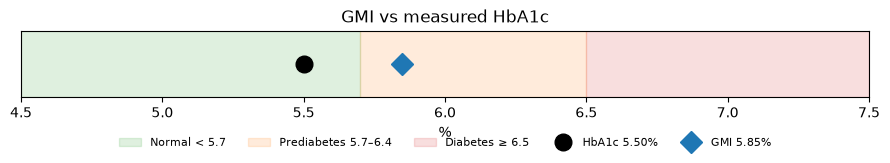

In [20]:
fig, ax = plt.subplots(figsize=(9, 2.2))

# Clinical bands
ax.axvspan(4.5, 5.7, color="#2ca02c", alpha=0.15, label="Normal < 5.7")
ax.axvspan(5.7, 6.5, color="#ff7f0e", alpha=0.15, label="Prediabetes 5.7–6.4")
ax.axvspan(6.5, 7.5, color="#d62728", alpha=0.15, label="Diabetes ≥ 6.5")

ax.plot(hba1c, 0, "o", ms=12, color="black", label=f"HbA1c {hba1c:.2f}%")
ax.plot(gmi, 0, "D", ms=11, color="tab:blue", label=f"GMI {gmi:.2f}%")

ax.set_xlim(4.5, 7.5)
ax.set_yticks([])
ax.set_xlabel("%")
ax.set_title("GMI vs measured HbA1c")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=5, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

---
## Summary

All Stage 2 answers in one table. Copy these into the notes section of `questions.md`.

The summary is also saved as a CSV so you can later combine results from all 16 participants.

In [21]:
summary = pd.Series({
    "Mean (mg/dL)": round(g.mean(), 1),
    "Median (mg/dL)": round(g.median(), 1),
    "Min (mg/dL)": g.min(),
    "Max (mg/dL)": g.max(),
    "SD (mg/dL)": round(g.std(), 1),
    "25th percentile": round(p25, 1),
    "75th percentile": round(p75, 1),
    "Skewness": round(skew, 2),
    "% < 70": tir.loc[labels[0], "% of time"],
    "% 70–140": tir.loc[labels[1], "% of time"],
    "% 140–180": tir.loc[labels[2], "% of time"],
    "% > 180": tir.loc[labels[3], "% of time"],
    "GMI (%)": round(gmi, 2),
    "HbA1c (%)": hba1c,
    "GMI − HbA1c": round(gmi - hba1c, 2),
}, name=PID)

summary.to_frame()

,001
Mean (mg/dL),106.10
Median (mg/dL),105.00
Min (mg/dL),46.00
Max (mg/dL),155.00
SD (mg/dL),15.80
25th percentile,95.00
75th percentile,114.00
Skewness,0.48
% < 70,0.90
% 70–140,95.50


In [22]:
summary.to_frame().T.rename_axis("participant").to_csv(f"../clean_data/stage2_summary_{PID}.csv")
print(f"Saved stage2_summary_{PID}.csv")

Saved stage2_summary_001.csv
